In [ ]:
# ============================================================
# CELL 1: Import the packages and set up the simulation
# ============================================================
#
# In this notebook we will study a simple 1D random walk.
#
# At every step, the walker moves either:
#
#     +1  -> one step to the right
#     -1  -> one step to the left
#
# For an unbiased random walk, both choices have probability 0.5.
#
# The goals of this notebook are to:
#   1. generate one random-walk trajectory,
#   2. compare several trajectories,
#   3. simulate many walkers,
#   4. examine position histograms at different step numbers,
#   5. calculate the average position,
#   6. calculate the mean-squared displacement (MSD).
#
# This provides a simple connection between random walks,
# Brownian motion, and diffusion.

# NumPy is used for numerical calculations and random numbers.
import numpy as np

# Matplotlib is used to make figures.
import matplotlib.pyplot as plt

# Set a random seed so that everyone obtains the same random
# sequence when they run the notebook.
np.random.seed(16)

print("Packages loaded successfully.")


Packages loaded successfully.


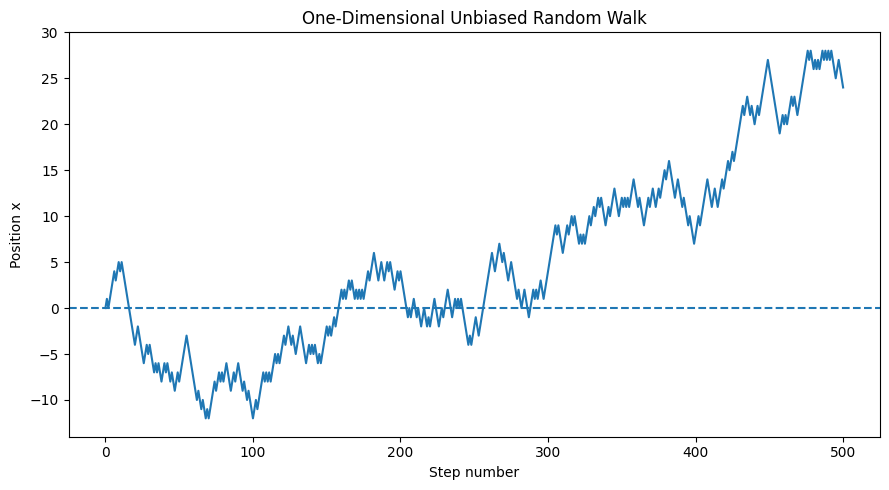

Final position after 500 steps: 24


In [ ]:
# ============================================================
# CELL 2: Generate ONE one-dimensional random walk
# ============================================================
#
# We first study a single walker.
#
# The walker begins at x = 0.
# At each step it randomly chooses either +1 or -1.
#
# Mathematically:
#
#     x_(n+1) = x_n + xi_n
#
# where xi_n is either +1 or -1 with equal probability.

# Number of steps in the walk.
n_steps = 500

# Generate the random steps.
#
# np.random.choice([-1, 1], size=n_steps)
# chooses either -1 or +1 independently at every step.
steps = np.random.choice(
    [-1, 1],
    size=n_steps
)

# Convert the sequence of steps into positions using a
# cumulative sum.
#
# Example:
#     steps = [+1, -1, +1, +1]
#
# gives:
#     cumulative positions = [1, 0, 1, 2]
#
# We add a zero at the beginning so the walker starts at x = 0.
position = np.concatenate(
    ([0], np.cumsum(steps))
)

# Create the step-number array from 0 through n_steps.
step_number = np.arange(n_steps + 1)

# Plot the random-walk trajectory.
plt.figure(figsize=(9, 5))
plt.plot(step_number, position)

# Label the axes and add a title.
plt.xlabel("Step number")
plt.ylabel("Position x")
plt.title("One-Dimensional Unbiased Random Walk")

# Add a reference line at x = 0.
plt.axhline(0, linestyle="--")

plt.tight_layout()
plt.show()

print("Final position after", n_steps, "steps:", position[-1])


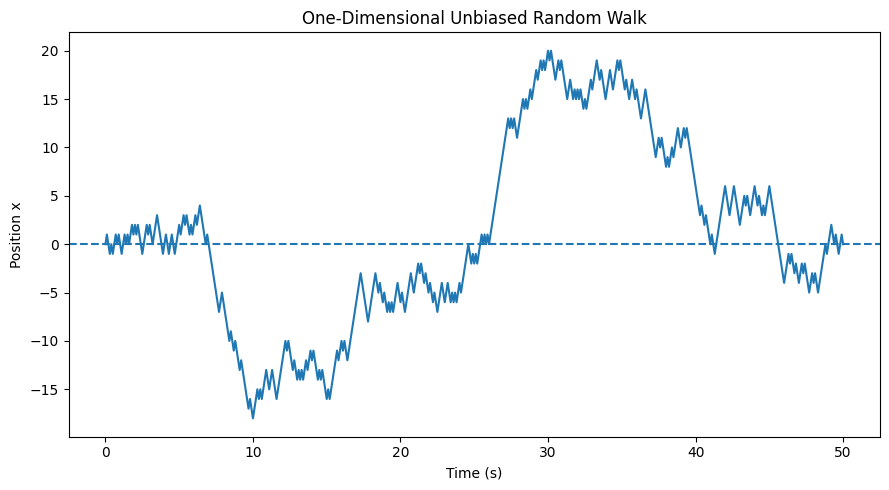

Final position after 500 steps: 0
Total simulation time: 50.0 seconds


In [ ]:
# ============================================================
# CELL 2: Generate ONE one-dimensional random walk
#         and plot position versus time
# ============================================================
#
# We first study a single walker.
#
# The walker begins at x = 0.
# At each step it randomly chooses either +1 or -1.
#
# Mathematically:
#
#     x_(n+1) = x_n + xi_n
#
# where xi_n is either +1 or -1 with equal probability.
#
# In this simulation:
#
#     1 step = 0.1 seconds
#
# Therefore:
#
#     time = step number × 0.1 s

# Number of steps in the walk.
n_steps = 500

# Time interval associated with one random-walk step.
dt = 0.1   # seconds

# Generate the random steps.
#
# np.random.choice([-1, 1], size=n_steps)
# chooses either -1 or +1 independently at every step.
steps = np.random.choice(
    [-1, 1],
    size=n_steps
)

# Convert the sequence of steps into positions using a
# cumulative sum.
#
# Example:
#     steps = [+1, -1, +1, +1]
#
# gives:
#     cumulative positions = [1, 0, 1, 2]
#
# We add a zero at the beginning so the walker starts at x = 0.
position = np.concatenate(
    ([0], np.cumsum(steps))
)

# Create the step-number array from 0 through n_steps.
step_number = np.arange(n_steps + 1)

# Convert step number into physical time.
#
# Since one step corresponds to 0.1 seconds:
#
#     time = step_number × 0.1
#
# For 500 steps, the final time is:
#
#     500 × 0.1 = 50 seconds
time = step_number * dt

# Plot the random-walk trajectory as position versus time.
plt.figure(figsize=(9, 5))

plt.plot(
    time,
    position
)

# Label the axes and add a title.
plt.xlabel("Time (s)")
plt.ylabel("Position x")
plt.title("One-Dimensional Unbiased Random Walk")

# Add a horizontal reference line at x = 0.
plt.axhline(
    0,
    linestyle="--"
)

plt.tight_layout()
plt.show()

# Print the final position and the total simulated time.
print("Final position after", n_steps, "steps:", position[-1])
print("Total simulation time:", time[-1], "seconds")

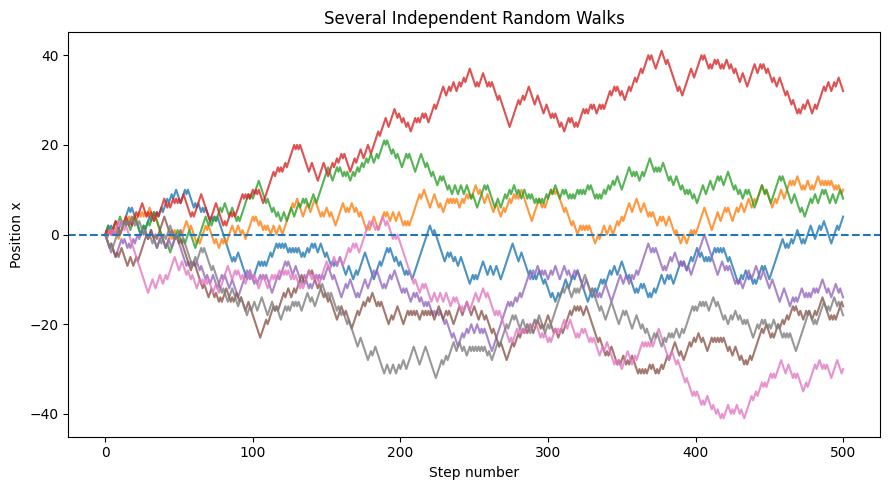

In [ ]:
# ============================================================
# CELL 3: Plot several independent random-walk trajectories
# ============================================================
#
# Every walker follows the same statistical rule:
#
#     P(+1) = 0.5
#     P(-1) = 0.5
#
# However, each walker receives a different random sequence
# of steps, so each trajectory looks different.

# Number of walkers that we want to display.
n_display_walkers = 8

plt.figure(figsize=(9, 5))

# Generate and plot each walker separately.
for walker in range(n_display_walkers):

    # Generate an independent sequence of +1 and -1 steps.
    walker_steps = np.random.choice(
        [-1, 1],
        size=n_steps
    )

    # Convert steps into positions and include the starting point x = 0.
    walker_position = np.concatenate(
        ([0], np.cumsum(walker_steps))
    )

    # Plot this walk.
    plt.plot(
        step_number,
        walker_position,
        alpha=0.8
    )

plt.xlabel("Step number")
plt.ylabel("Position x")
plt.title("Several Independent Random Walks")
plt.axhline(0, linestyle="--")

plt.tight_layout()
plt.show()


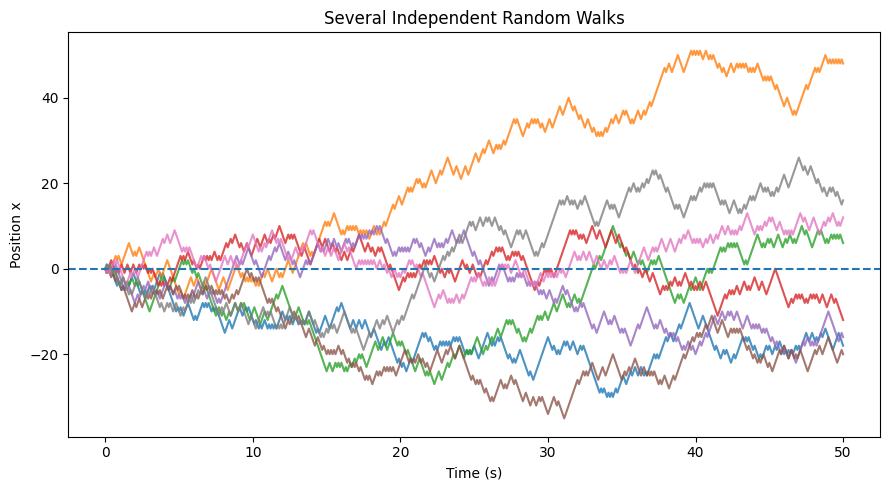

In [ ]:
# ============================================================
# CELL 3: Plot several independent random-walk trajectories
#         as position versus time
# ============================================================
#
# Every walker follows the same statistical rule:
#
#     P(+1) = 0.5
#     P(-1) = 0.5
#
# However, each walker receives a different random sequence
# of steps, so each trajectory looks different.
#
# In this simulation:
#
#     1 step = 0.1 seconds
#
# Therefore, the time array created in Cell 2 is:
#
#     time = step_number * dt
#
# For 500 steps:
#
#     total time = 500 * 0.1 = 50 seconds

# Number of walkers that we want to display.
n_display_walkers = 8

# Create a new figure.
plt.figure(figsize=(9, 5))

# Generate and plot each walker separately.
for walker in range(n_display_walkers):

    # Generate an independent sequence of +1 and -1 steps.
    #
    # Each walker follows the same probabilities:
    #
    #     P(+1) = 0.5
    #     P(-1) = 0.5
    #
    # but receives a different random sequence.
    walker_steps = np.random.choice(
        [-1, 1],
        size=n_steps
    )

    # Convert the sequence of steps into positions using
    # the cumulative sum.
    #
    # We include the initial position x = 0 at time t = 0.
    walker_position = np.concatenate(
        ([0], np.cumsum(walker_steps))
    )

    # Plot this walk as position versus physical time.
    #
    # The time array runs from:
    #
    #     0 s to 50 s
    #
    # because each step corresponds to 0.1 s.
    plt.plot(
        time,
        walker_position,
        alpha=0.8
    )

# Label the axes.
plt.xlabel("Time (s)")
plt.ylabel("Position x")

# Add a descriptive title.
plt.title("Several Independent Random Walks")

# Add a horizontal reference line at x = 0.
plt.axhline(
    0,
    linestyle="--"
)

# Adjust spacing and display the figure.
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 4: Simulate a large ensemble of random walkers
# ============================================================
#
# A single trajectory does not tell us the statistical behavior
# of the system. We therefore simulate many independent walkers.
#
# Each row of the final array represents one walker.
# Each column represents one step number.

# Number of independent walkers.
n_walkers = 1000

# Number of steps for every walker.
n_steps = 500

# Generate all random steps at once.
#
# This array has shape:
#
#     (n_walkers, n_steps)
#
# which here is:
#
#     (1000, 500)
all_steps = np.random.choice(
    [-1, 1],
    size=(n_walkers, n_steps)
)

# Calculate the cumulative position for each walker.
#
# axis=1 means that the cumulative sum is performed across
# the steps for each row separately.
positions_without_start = np.cumsum(
    all_steps,
    axis=1
)

# Create one starting position x = 0 for every walker.
initial_positions = np.zeros(
    (n_walkers, 1),
    dtype=int
)

# Add the starting-position column to the calculated positions.
positions = np.concatenate(
    (initial_positions, positions_without_start),
    axis=1
)

# Recreate the step-number array.
step_number = np.arange(n_steps + 1)

print("Shape of positions array:", positions.shape)
print("Number of walkers:", positions.shape[0])
print("Number of recorded step positions:", positions.shape[1])


Shape of positions array: (1000, 501)
Number of walkers: 1000
Number of recorded step positions: 501


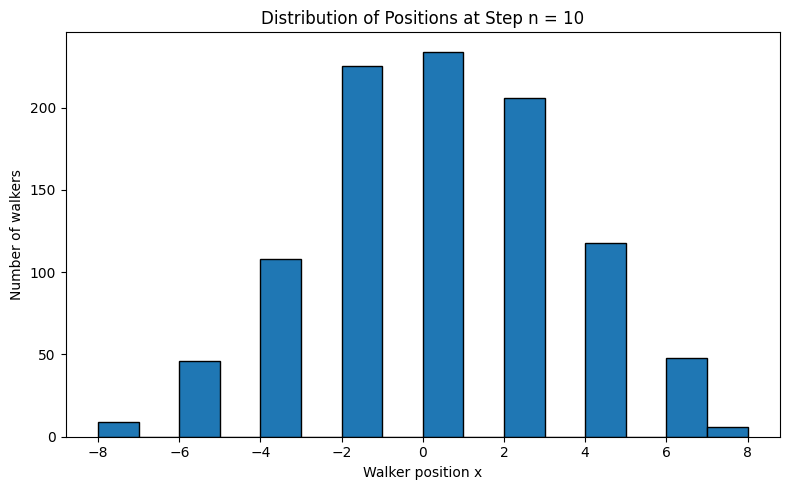

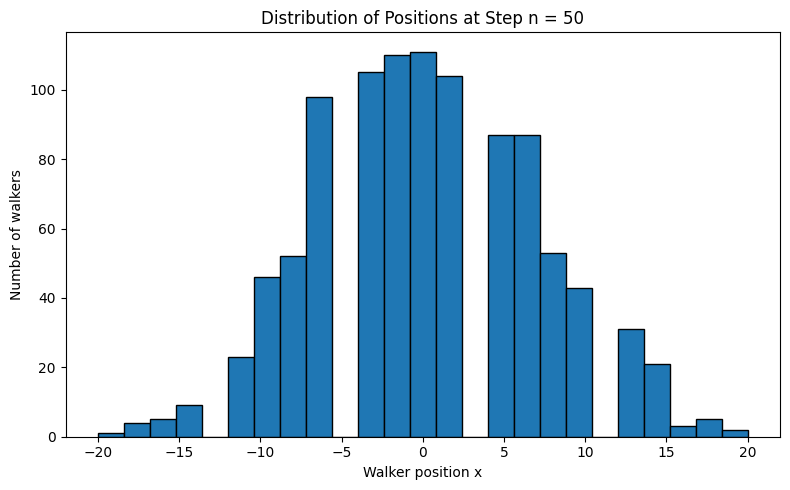

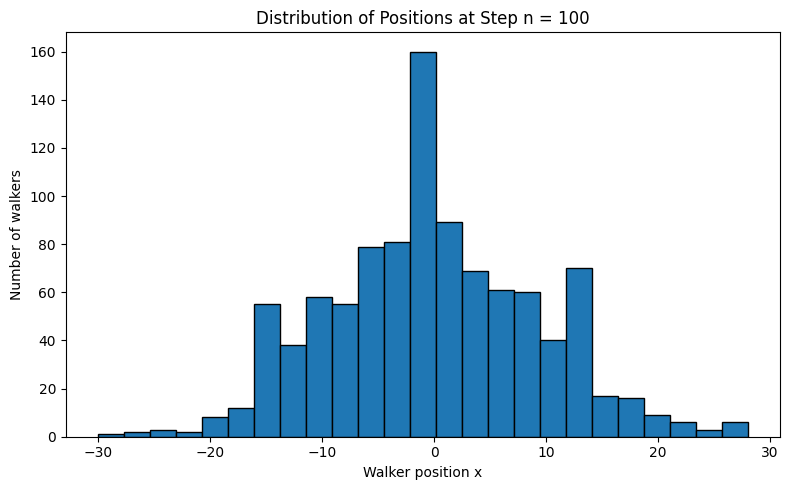

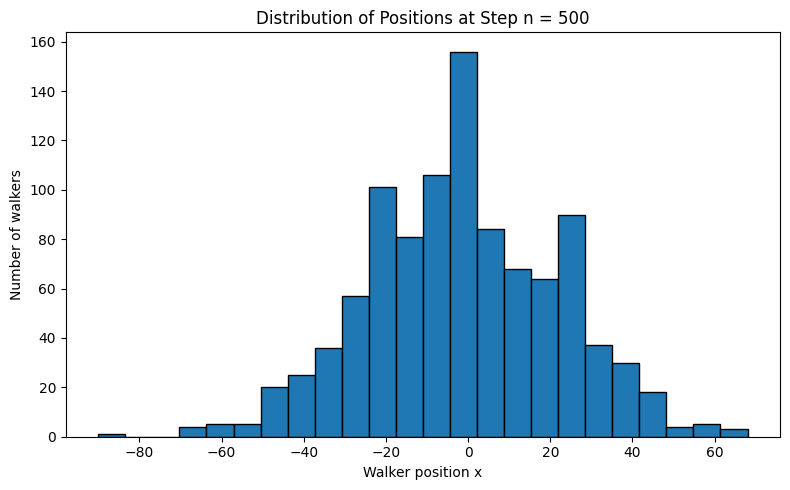

In [ ]:
# ============================================================
# CELL 5: Make histograms of walker positions
# ============================================================
#
# We now ask:
#
#     Where are the 1000 walkers after a certain number of steps?
#
# We examine the distribution of walker positions at:
#
#     n = 10, 50, 100, and 500
#
# At early times, the walkers are concentrated closer to x = 0.
# At later times, the distribution spreads out.
#
# For a large number of steps, the distribution approaches
# a Gaussian shape.

# Step numbers at which we want to examine the distribution.
times_to_plot = [10, 50, 100, 500]

# Loop over the selected step numbers.
for n in times_to_plot:

    # positions[:, n] means:
    # use ALL walkers and select their positions at step n.
    positions_at_n = positions[:, n]

    # Make the histogram.
    plt.figure(figsize=(8, 5))
    plt.hist(
        positions_at_n,
        bins="auto",
        edgecolor="black"
    )

    plt.xlabel("Walker position x")
    plt.ylabel("Number of walkers")
    plt.title(f"Distribution of Positions at Step n = {n}")

    plt.tight_layout()
    plt.show()


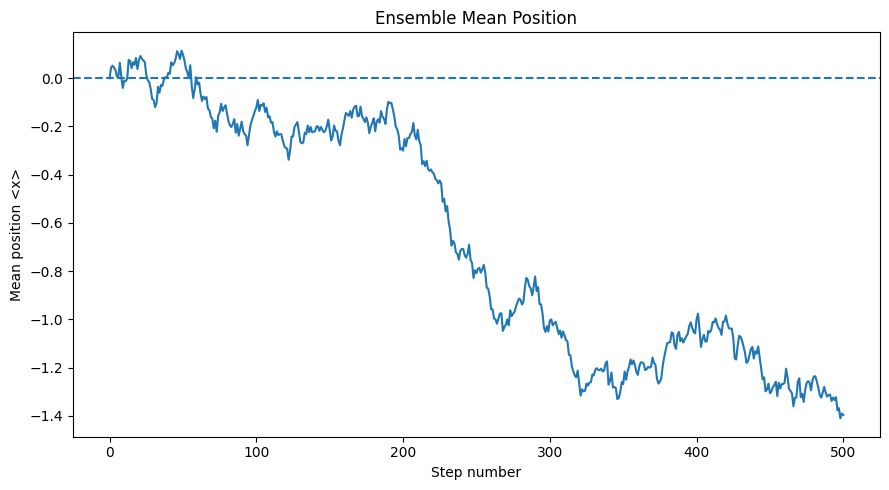

Mean position at the final step: -1.396


In [ ]:
# ============================================================
# CELL 6: Calculate the ensemble mean position <x>
# ============================================================
#
# At every step, we have the positions of 1000 walkers.
#
# The ensemble mean position is:
#
#     <x(n)> = average position of all walkers at step n
#
# Because the walk is unbiased:
#
#     P(+1) = P(-1) = 0.5
#
# there is no preferred direction.
#
# Therefore, theoretically:
#
#     <x(n)> = 0
#
# In the simulation, the result will fluctuate slightly around zero
# because we have only a finite number of walkers.

# Average over all walkers.
#
# axis=0 means:
# average down the rows, leaving one value for each step number.
mean_position = np.mean(
    positions,
    axis=0
)

# Plot the ensemble mean position.
plt.figure(figsize=(9, 5))
plt.plot(step_number, mean_position)

# Add a zero reference line.
plt.axhline(0, linestyle="--")

plt.xlabel("Step number")
plt.ylabel("Mean position <x>")
plt.title("Ensemble Mean Position")

plt.tight_layout()
plt.show()

print("Mean position at the final step:", mean_position[-1])


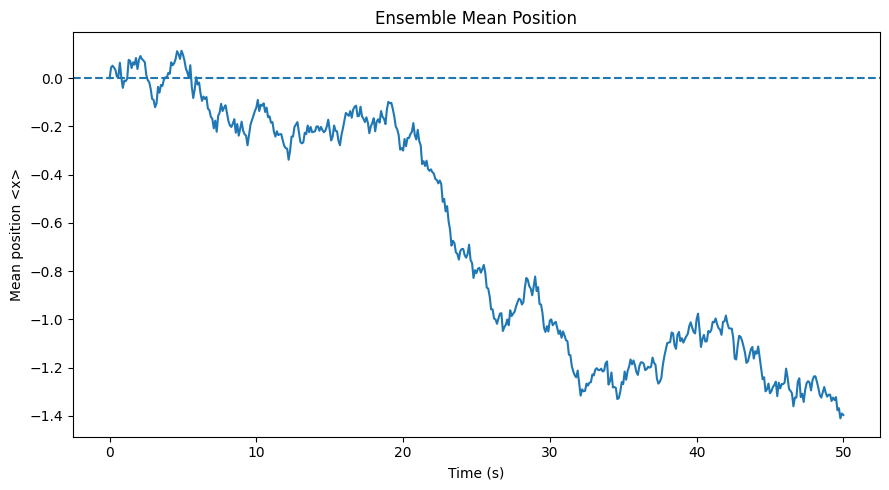

Mean position at the final time: -1.396
Final time: 50.0 seconds


In [ ]:
# ============================================================
# CELL 6: Calculate the ensemble mean position <x>
#         and plot it versus time
# ============================================================
#
# At every time point, we have the positions of 1000 walkers.
#
# The ensemble mean position is:
#
#     <x(t)> = average position of all walkers at time t
#
# Because the walk is unbiased:
#
#     P(+1) = P(-1) = 0.5
#
# there is no preferred direction.
#
# Therefore, theoretically:
#
#     <x(t)> = 0
#
# In the simulation, the result will fluctuate slightly around zero
# because we have only a finite number of walkers.
#
# In this simulation:
#
#     1 step = 0.1 seconds
#
# Therefore:
#
#     time = step_number * 0.1

# Average over all walkers.
#
# axis=0 means:
# average down the rows, leaving one mean-position value
# for each recorded time point.
mean_position = np.mean(
    positions,
    axis=0
)

# Convert the step-number array into physical time.
#
# dt was defined earlier as:
#
#     dt = 0.1   # seconds
#
# Therefore, for 500 steps:
#
#     total time = 500 * 0.1 = 50 seconds
time = step_number * dt

# Plot the ensemble mean position versus physical time.
plt.figure(figsize=(9, 5))

plt.plot(
    time,
    mean_position
)

# Add a horizontal reference line at <x> = 0.
plt.axhline(
    0,
    linestyle="--"
)

# Label the axes.
plt.xlabel("Time (s)")
plt.ylabel("Mean position <x>")

# Add a descriptive title.
plt.title("Ensemble Mean Position")

# Adjust spacing and display the figure.
plt.tight_layout()
plt.show()

# Print the ensemble mean position at the final time point.
print(
    "Mean position at the final time:",
    mean_position[-1]
)

print(
    "Final time:",
    time[-1],
    "seconds"
)

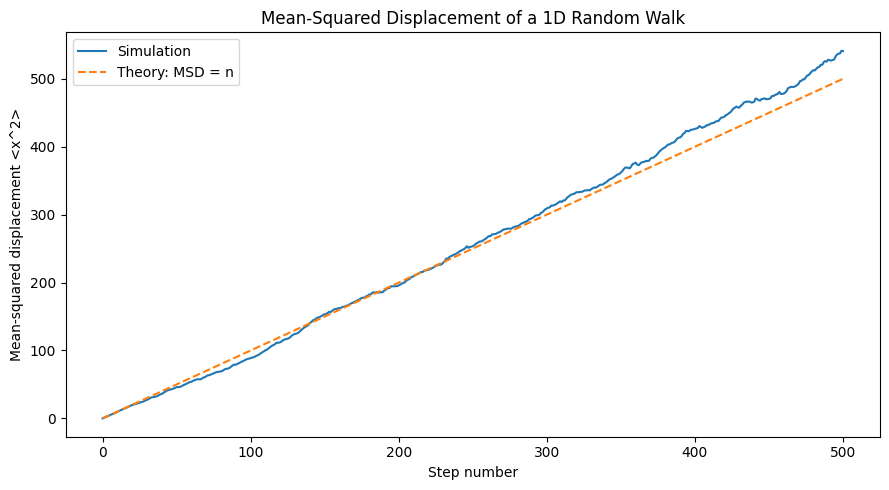

In [ ]:
# ============================================================
# CELL 7: Calculate the Mean-Squared Displacement (MSD)
# ============================================================
#
# Even though the average position remains close to zero,
# the walkers spread farther away from the origin as time passes.
#
# We measure this spreading using the mean-squared displacement:
#
#     MSD(n) = <x(n)^2>
#
# Since all walkers start at x = 0, this is simply the average
# of x^2 over all walkers.
#
# For an unbiased 1D random walk with step size 1:
#
#     <x^2(n)> = n
#
# Therefore, the MSD should grow approximately linearly
# with step number.

# Square every position.
squared_positions = positions**2

# Average x^2 over all walkers at each step.
msd = np.mean(
    squared_positions,
    axis=0
)

# Plot the simulated MSD.
plt.figure(figsize=(9, 5))
plt.plot(
    step_number,
    msd,
    label="Simulation"
)

# Plot the theoretical result MSD = n.
plt.plot(
    step_number,
    step_number,
    linestyle="--",
    label="Theory: MSD = n"
)

plt.xlabel("Step number")
plt.ylabel("Mean-squared displacement <x^2>")
plt.title("Mean-Squared Displacement of a 1D Random Walk")
plt.legend()

plt.tight_layout()
plt.show()


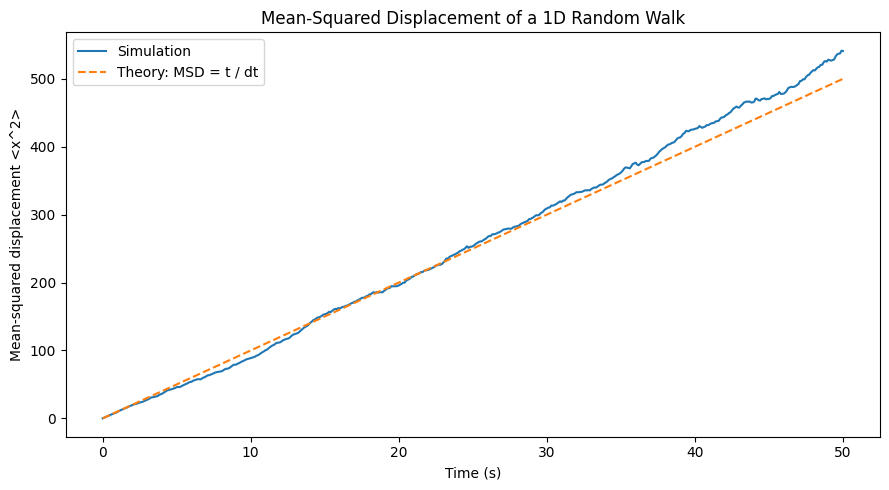

In [ ]:
# ============================================================
# CELL 7: Calculate the Mean-Squared Displacement (MSD)
#         and plot it versus time
# ============================================================
#
# Even though the average position remains close to zero,
# the walkers spread farther away from the origin as time passes.
#
# We measure this spreading using the mean-squared displacement:
#
#     MSD(t) = <x(t)^2>
#
# Since all walkers start at x = 0, this is simply the average
# of x^2 over all walkers.
#
# For an unbiased 1D random walk with step size 1:
#
#     <x^2(n)> = n
#
# where n is the number of steps.
#
# In this simulation:
#
#     1 step = dt = 0.1 seconds
#
# Since:
#
#     time = n * dt
#
# we can write:
#
#     n = time / dt
#
# Therefore:
#
#     <x^2(t)> = time / dt
#
# Since dt = 0.1 s:
#
#     <x^2(t)> = 10 * time
#
# Therefore, the MSD should grow approximately linearly with time.

# Square every walker position.
squared_positions = positions**2

# Average x^2 over all walkers at each time point.
#
# axis=0 means that we average over all walkers while
# keeping the individual time points separate.
msd = np.mean(
    squared_positions,
    axis=0
)

# Convert step number to physical time.
#
# dt was defined earlier as:
#
#     dt = 0.1   # seconds
time = step_number * dt

# Plot the simulated MSD versus time.
plt.figure(figsize=(9, 5))

plt.plot(
    time,
    msd,
    label="Simulation"
)

# Calculate the theoretical MSD in terms of physical time.
#
# For this unit-step random walk:
#
#     MSD = n
#
# and because:
#
#     n = time / dt
#
# the theoretical result becomes:
#
#     MSD = time / dt
theoretical_msd = time / dt

# Plot the theoretical result.
plt.plot(
    time,
    theoretical_msd,
    linestyle="--",
    label="Theory: MSD = t / dt"
)

# Label the axes.
plt.xlabel("Time (s)")
plt.ylabel("Mean-squared displacement <x^2>")

# Add a descriptive title.
plt.title("Mean-Squared Displacement of a 1D Random Walk")

# Display the legend.
plt.legend()

# Adjust spacing and display the figure.
plt.tight_layout()
plt.show()

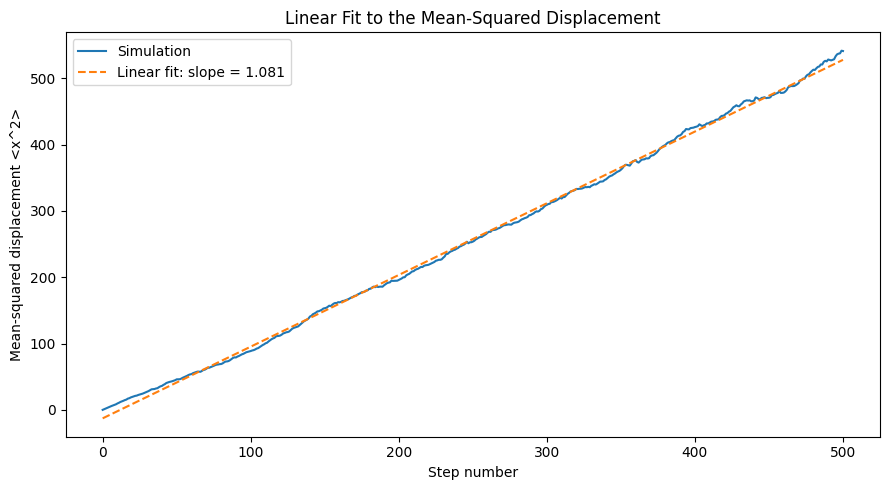

Fitted slope: 1.0807984899682714
Fitted intercept: -12.78616141422329


In [ ]:
# ============================================================
# CELL 8: Fit the MSD with a straight line
# ============================================================
#
# For normal diffusion:
#
#     MSD is proportional to time
#
# In this discrete random-walk simulation, the step number
# plays the role of time.
#
# We fit:
#
#     MSD = slope * n + intercept
#
# For this particular random walk, the expected slope is
# approximately 1.

# Fit a straight line to the MSD data.
#
# np.polyfit(x, y, 1) performs a first-order polynomial fit.
slope, intercept = np.polyfit(
    step_number,
    msd,
    1
)

# Calculate the fitted line.
msd_fit = slope * step_number + intercept

# Plot the MSD and its linear fit.
plt.figure(figsize=(9, 5))

plt.plot(
    step_number,
    msd,
    label="Simulation"
)

plt.plot(
    step_number,
    msd_fit,
    linestyle="--",
    label=f"Linear fit: slope = {slope:.3f}"
)

plt.xlabel("Step number")
plt.ylabel("Mean-squared displacement <x^2>")
plt.title("Linear Fit to the Mean-Squared Displacement")
plt.legend()

plt.tight_layout()
plt.show()

print("Fitted slope:", slope)
print("Fitted intercept:", intercept)


In [ ]:
# ============================================================
# CELL 9: Student exploration
# ============================================================
#
# Use the notebook above as a starting point and explore how
# the random-walk behavior changes when you modify the model.
#
# Exercise 1:
# Change n_steps from 500 to 1000.
# Run the simulation again.
# How does the width of the position distribution change?
#
# Exercise 2:
# Change n_walkers from 1000 to 100.
# Then try 5000 walkers.
# How do the plots of <x> and MSD change?
#
# Exercise 3:
# Create a biased random walk.
#
# Instead of:
#
#     P(+1) = 0.5
#     P(-1) = 0.5
#
# try:
#
#     P(+1) = 0.6
#     P(-1) = 0.4
#
# You can generate the biased steps using:
#
# all_steps = np.random.choice(
#     [-1, 1],
#     size=(n_walkers, n_steps),
#     p=[0.4, 0.6]
# )
#
# After changing the probabilities, examine:
#
#     the trajectories,
#     the position distribution,
#     the mean position <x>,
#     the mean-squared displacement.
#
# Think about this question:
#
# Does <x> still remain close to zero for a biased walk?
#
# Write your modified code below.
